In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import joblib
import gc
import time

import pyarrow.parquet as pq

import xgboost as xgb
import lightgbm as lgb

from pathlib import Path

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
N_JOBS = 2

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")

MODEL_PATH.mkdir(parents=True, exist_ok=True)
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

In [2]:
with open(DATA_PATH / "feature_metadata.json", "r") as f:
    metadata = json.load(f)

feature_columns = metadata["feature_columns"]
feature_groups = metadata["feature_groups"]
target_column = metadata["target_column"]

baseline_results = pd.read_csv(
    RESULTS_PATH / "baseline_model_results.csv"
)

baseline_results

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives
0,Logistic Regression,0.5,0.993420,0.981132,0.033505,0.064798,0.394360,0.931000,0.147823,52,1,226550,1500
1,Balanced Logistic Regression,0.5,0.774554,0.027351,0.929768,0.053138,0.326533,0.948812,0.986851,1443,51316,175235,109
2,B - Transaction + Temporal,0.5,0.839314,0.035787,0.871778,0.068752,0.168465,0.932775,0.972272,1353,36454,190097,199
3,C - Transaction + Behavioral,0.5,0.661271,0.018837,0.954897,0.036944,0.163731,0.917962,0.993247,1482,77195,149356,70
4,A - Transaction Only,0.5,0.774882,0.025824,0.873711,0.050165,0.095399,0.905747,0.989581,1356,51154,175397,196
5,PaySim Fraud Rule,0.5,0.993205,1.000000,0.001289,0.002574,0.008084,0.500644,0.001933,2,0,226551,1550


In [3]:
NEGATIVE_SAMPLE_RATE = 0.05
BATCH_SIZE = 100_000

def load_training_sample(
    sample_rate=0.05,
    batch_size=100_000
):

    rng = np.random.default_rng(RANDOM_STATE)

    train_file = pq.ParquetFile(
        DATA_PATH / "train.parquet"
    )

    sampled_batches = []

    for batch in train_file.iter_batches(
        batch_size=batch_size,
        columns=feature_columns + [target_column]
    ):

        chunk = batch.to_pandas()

        fraud_mask = chunk[target_column] == 1

        random_mask = rng.random(len(chunk)) < sample_rate

        keep_mask = fraud_mask | random_mask

        sampled_batches.append(
            chunk.loc[keep_mask].copy()
        )

        del chunk

    sampled_data = pd.concat(
        sampled_batches,
        ignore_index=True
    )

    del sampled_batches
    gc.collect()

    return sampled_data

In [4]:
train_df = load_training_sample(
    sample_rate=NEGATIVE_SAMPLE_RATE,
    batch_size=BATCH_SIZE
)

print("Training shape:", train_df.shape)

train_df[target_column].value_counts()

Training shape: (305142, 13)


isFraud
0    300135
1      5007
Name: count, dtype: int64

In [5]:
val_df = pd.read_parquet(
    DATA_PATH / "validation.parquet",
    columns=feature_columns + [target_column]
)

print("Validation shape:", val_df.shape)

Validation shape: (228103, 13)


In [6]:
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_val = val_df[feature_columns]
y_val = val_df[target_column]

In [7]:
def create_tree_preprocessor():

    categorical_features = ["type"]

    numerical_features = [
        col for col in feature_columns
        if col not in categorical_features
    ]

    return ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                    dtype=np.float32
                ),
                categorical_features
            ),
            (
                "numerical",
                "passthrough",
                numerical_features
            )
        ],
        verbose_feature_names_out=False
    ).set_output(transform="pandas")

In [8]:
preprocessor = create_tree_preprocessor()

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

X_train_processed.head()

Processed training shape: (305142, 16)
Processed validation shape: (228103, 16)


,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER,amount,log_amount,recipient_is_merchant,hour_sin,hour_cos,recipient_prior_count,recipient_prior_total,recipient_prior_mean,recipient_hours_since_last,recipient_is_new,amount_to_recipient_mean
0,0.0,0.0,0.0,0.0,1.0,181.00,5.204007,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
1,0.0,1.0,0.0,0.0,0.0,181.00,5.204007,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
2,0.0,0.0,0.0,1.0,0.0,8009.09,8.988457,1,0.0,1.0,0,0.0,NaN,NaN,1,NaN
3,0.0,1.0,0.0,0.0,0.0,23261.30,10.054589,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN
4,0.0,0.0,1.0,0.0,0.0,5149.66,8.546880,0,0.0,1.0,0,0.0,NaN,NaN,1,NaN


In [9]:
population_weights = np.where(
    y_train == 1,
    1.0,
    1.0 / NEGATIVE_SAMPLE_RATE
)

population_weights = (
    population_weights / population_weights.mean()
)

In [10]:
balanced_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

In [11]:
weighting_strategies = {
    "Population Weighted": population_weights,
    "Class Balanced": balanced_weights
}

In [12]:
results = []
predictions = {}
trained_models = {}
experiment_configs = {}

def evaluate_model(
    model_name,
    y_true,
    y_score,
    amounts,
    threshold=0.5
):

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    amounts = np.asarray(amounts, dtype=np.float64)

    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_fraud_amount = amounts[y_true == 1].sum()

    detected_fraud_amount = amounts[
        (y_true == 1) & (y_pred == 1)
    ].sum()

    metrics = {
        "model": model_name,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_true, y_score
        ),
        "roc_auc": roc_auc_score(y_true, y_score),
        "fraud_value_captured": (
            detected_fraud_amount / total_fraud_amount
            if total_fraud_amount > 0 else 0
        ),
        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn
    }

    return metrics

In [13]:
xgb_params = {
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "n_estimators": 800,
    "learning_rate": 0.05,
    "max_depth": 5,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "tree_method": "hist",
    "early_stopping_rounds": 40,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS
}

In [14]:
lgb_params = {
    "objective": "binary",
    "metric": "average_precision",
    "boosting_type": "gbdt",
    "n_estimators": 800,
    "learning_rate": 0.05,
    "max_depth": 5,
    "num_leaves": 31,
    "min_child_samples": 50,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "importance_type": "gain",
    "force_col_wise": True,
    "random_state": RANDOM_STATE,
    "n_jobs": N_JOBS,
    "verbosity": -1
}

In [15]:
def train_boosting_model(
    model_name,
    algorithm,
    params,
    sample_weights,
    train_features,
    train_target,
    fitted_preprocessor,
    validation_features,
    sample_rate=NEGATIVE_SAMPLE_RATE,
    weighting_name=None
):

    start_time = time.perf_counter()

    if algorithm == "xgboost":

        model = xgb.XGBClassifier(**params)

        model.fit(
            train_features,
            train_target,
            sample_weight=sample_weights,
            eval_set=[
                (validation_features, y_val)
            ],
            verbose=False
        )

        best_iteration = model.best_iteration + 1

    elif algorithm == "lightgbm":

        model = lgb.LGBMClassifier(**params)

        model.fit(
            train_features,
            train_target,
            sample_weight=sample_weights,
            eval_set=[
                (validation_features, y_val)
            ],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=40,
                    first_metric_only=True,
                    verbose=False
                ),
                lgb.log_evaluation(period=0)
            ]
        )

        best_iteration = model.best_iteration_

    else:
        raise ValueError("Unsupported algorithm")

    training_time = time.perf_counter() - start_time

    probabilities = model.predict_proba(
        validation_features
    )[:, 1]

    metrics = evaluate_model(
        model_name,
        y_val,
        probabilities,
        val_df["amount"]
    )

    metrics["algorithm"] = algorithm
    metrics["training_time_seconds"] = training_time
    metrics["best_iteration"] = best_iteration
    metrics["training_rows"] = len(train_target)
    metrics["negative_sample_rate"] = sample_rate
    metrics["weighting"] = weighting_name

    results.append(metrics)

    predictions[model_name] = probabilities

    trained_models[model_name] = Pipeline([
        ("preprocessor", fitted_preprocessor),
        ("classifier", model)
    ])

    experiment_configs[model_name] = params.copy()

    gc.collect()

    return pd.Series(metrics)

In [16]:
train_boosting_model(
    model_name="XGBoost - Population Weighted",
    algorithm="xgboost",
    params=xgb_params,
    sample_weights=population_weights,
    train_features=X_train_processed,
    train_target=y_train,
    fitted_preprocessor=preprocessor,
    validation_features=X_val_processed,
    weighting_name="population"
)

model                    XGBoost - Population Weighted
threshold                                          0.5
accuracy                                      0.993998
precision                                     0.994595
recall                                        0.118557
f1                                             0.21186
average_precision                             0.580715
roc_auc                                       0.966844
fraud_value_captured                            0.2872
true_positives                                     184
false_positives                                      1
true_negatives                                  226550
false_negatives                                   1368
algorithm                                      xgboost
training_time_seconds                          8.74788
best_iteration                                      58
training_rows                                   305142
negative_sample_rate                              0.05
weighting 

In [17]:
train_boosting_model(
    model_name="XGBoost - Class Balanced",
    algorithm="xgboost",
    params=xgb_params,
    sample_weights=balanced_weights,
    train_features=X_train_processed,
    train_target=y_train,
    fitted_preprocessor=preprocessor,
    validation_features=X_val_processed,
    weighting_name="balanced"
)

model                    XGBoost - Class Balanced
threshold                                     0.5
accuracy                                  0.93979
precision                                0.092029
recall                                   0.885309
f1                                       0.166727
average_precision                        0.580213
roc_auc                                  0.975219
fraud_value_captured                     0.987115
true_positives                               1374
false_positives                             13556
true_negatives                             212995
false_negatives                               178
algorithm                                 xgboost
training_time_seconds                   10.443056
best_iteration                                108
training_rows                              305142
negative_sample_rate                         0.05
weighting                                balanced
dtype: object

In [18]:
train_boosting_model(
    model_name="LightGBM - Population Weighted",
    algorithm="lightgbm",
    params=lgb_params,
    sample_weights=population_weights,
    train_features=X_train_processed,
    train_target=y_train,
    fitted_preprocessor=preprocessor,
    validation_features=X_val_processed,
    weighting_name="population"
)

/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


model                    LightGBM - Population Weighted
threshold                                           0.5
accuracy                                       0.993924
precision                                           1.0
recall                                         0.106959
f1                                             0.193248
average_precision                              0.590204
roc_auc                                        0.971202
fraud_value_captured                           0.325844
true_positives                                      166
false_positives                                       0
true_negatives                                   226551
false_negatives                                    1386
algorithm                                      lightgbm
training_time_seconds                          2.185153
best_iteration                                       21
training_rows                                    305142
negative_sample_rate                            

In [19]:
train_boosting_model(
    model_name="LightGBM - Class Balanced",
    algorithm="lightgbm",
    params=lgb_params,
    sample_weights=balanced_weights,
    train_features=X_train_processed,
    train_target=y_train,
    fitted_preprocessor=preprocessor,
    validation_features=X_val_processed,
    weighting_name="balanced"
)

/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


model                    LightGBM - Class Balanced
threshold                                      0.5
accuracy                                  0.940777
precision                                 0.093272
recall                                    0.883376
f1                                        0.168728
average_precision                         0.579871
roc_auc                                   0.975264
fraud_value_captured                      0.987424
true_positives                                1371
false_positives                              13328
true_negatives                              213223
false_negatives                                181
algorithm                                 lightgbm
training_time_seconds                     5.042681
best_iteration                                 112
training_rows                               305142
negative_sample_rate                          0.05
weighting                                 balanced
dtype: object

In [20]:
initial_results = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

initial_results.round(6)

,model,threshold,accuracy,precision,recall,f1,average_precision,roc_auc,fraud_value_captured,true_positives,false_positives,true_negatives,false_negatives,algorithm,training_time_seconds,best_iteration,training_rows,negative_sample_rate,weighting
0,LightGBM - Population Weighted,0.5,0.993924,1.000000,0.106959,0.193248,0.590204,0.971202,0.325844,166,0,226551,1386,lightgbm,2.185153,21,305142,0.05,population
1,XGBoost - Population Weighted,0.5,0.993998,0.994595,0.118557,0.211860,0.580715,0.966844,0.287200,184,1,226550,1368,xgboost,8.747880,58,305142,0.05,population
2,XGBoost - Class Balanced,0.5,0.939790,0.092029,0.885309,0.166727,0.580213,0.975219,0.987115,1374,13556,212995,178,xgboost,10.443056,108,305142,0.05,balanced
3,LightGBM - Class Balanced,0.5,0.940777,0.093272,0.883376,0.168728,0.579871,0.975264,0.987424,1371,13328,213223,181,lightgbm,5.042681,112,305142,0.05,balanced


In [21]:
comparison_columns = [
    "model",
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "fraud_value_captured",
    "false_positives",
    "training_time_seconds",
    "best_iteration"
]

initial_results[comparison_columns].round(6)

,model,average_precision,roc_auc,precision,recall,f1,fraud_value_captured,false_positives,training_time_seconds,best_iteration
0,LightGBM - Population Weighted,0.590204,0.971202,1.000000,0.106959,0.193248,0.325844,0,2.185153,21
1,XGBoost - Population Weighted,0.580715,0.966844,0.994595,0.118557,0.211860,0.287200,1,8.747880,58
2,XGBoost - Class Balanced,0.580213,0.975219,0.092029,0.885309,0.166727,0.987115,13556,10.443056,108
3,LightGBM - Class Balanced,0.579871,0.975264,0.093272,0.883376,0.168728,0.987424,13328,5.042681,112


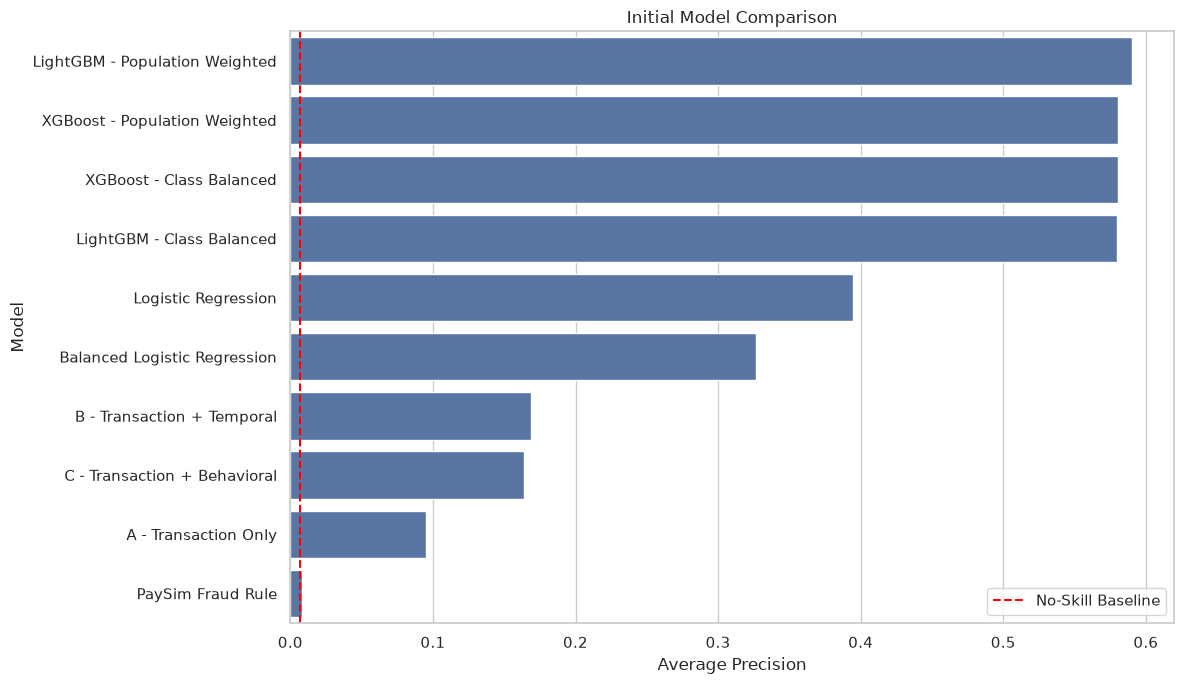

In [22]:
initial_comparison = pd.concat(
    [baseline_results, initial_results],
    ignore_index=True
).sort_values(
    "average_precision",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=initial_comparison,
    x="average_precision",
    y="model"
)

plt.axvline(
    y_val.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Initial Model Comparison")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
xgb_tuning_configs = {
    "Shallow": {
        "max_depth": 3,
        "min_child_weight": 10
    },
    "Deep": {
        "max_depth": 7,
        "min_child_weight": 5
    },
    "Regularized": {
        "max_depth": 5,
        "min_child_weight": 10,
        "reg_alpha": 1.0,
        "reg_lambda": 5.0
    },
    "Slow Learning": {
        "learning_rate": 0.02,
        "n_estimators": 1500,
        "max_depth": 5
    }
}

In [24]:
lgb_tuning_configs = {
    "Shallow": {
        "max_depth": 3,
        "num_leaves": 7
    },
    "Deep": {
        "max_depth": 7,
        "num_leaves": 63
    },
    "Regularized": {
        "max_depth": 5,
        "num_leaves": 31,
        "min_child_samples": 100,
        "reg_alpha": 1.0,
        "reg_lambda": 5.0
    },
    "Slow Learning": {
        "learning_rate": 0.02,
        "n_estimators": 1500
    }
}

In [25]:
best_xgb_initial = (
    initial_results[
        initial_results["algorithm"] == "xgboost"
    ].iloc[0]
)

best_lgb_initial = (
    initial_results[
        initial_results["algorithm"] == "lightgbm"
    ].iloc[0]
)

print("Best XGBoost weighting:",
      best_xgb_initial["weighting"])

print("Best LightGBM weighting:",
      best_lgb_initial["weighting"])

Best XGBoost weighting: population
Best LightGBM weighting: population


In [26]:
weights_lookup = {
    "population": population_weights,
    "balanced": balanced_weights
}

In [27]:
for config_name, config in xgb_tuning_configs.items():

    params = {
        **xgb_params,
        **config
    }

    weighting = best_xgb_initial["weighting"]

    metrics = train_boosting_model(
        model_name=f"XGBoost - {config_name}",
        algorithm="xgboost",
        params=params,
        sample_weights=weights_lookup[weighting],
        train_features=X_train_processed,
        train_target=y_train,
        fitted_preprocessor=preprocessor,
        validation_features=X_val_processed,
        weighting_name=weighting
    )

    print(
        f"{config_name}: "
        f"AP = {metrics['average_precision']:.6f}"
    )

Shallow: AP = 0.603106
Deep: AP = 0.589572
Regularized: AP = 0.593509
Slow Learning: AP = 0.586666


In [28]:
for config_name, config in lgb_tuning_configs.items():

    params = {
        **lgb_params,
        **config
    }

    weighting = best_lgb_initial["weighting"]

    metrics = train_boosting_model(
        model_name=f"LightGBM - {config_name}",
        algorithm="lightgbm",
        params=params,
        sample_weights=weights_lookup[weighting],
        train_features=X_train_processed,
        train_target=y_train,
        fitted_preprocessor=preprocessor,
        validation_features=X_val_processed,
        weighting_name=weighting
    )

    print(
        f"{config_name}: "
        f"AP = {metrics['average_precision']:.6f}"
    )

/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Shallow: AP = 0.577783


/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Deep: AP = 0.587081


/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Regularized: AP = 0.579951


/mnt/c/Users/Nathan Huang/fraud-detection-platform/.venv/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Slow Learning: AP = 0.589129


In [29]:
results_df = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

results_df[comparison_columns].round(6)

,model,average_precision,roc_auc,precision,recall,f1,fraud_value_captured,false_positives,training_time_seconds,best_iteration
0,XGBoost - Shallow,0.603106,0.969962,0.975309,0.203608,0.336887,0.455257,8,15.069758,164
1,XGBoost - Regularized,0.593509,0.967893,0.994792,0.123067,0.219037,0.289049,1,8.986205,102
2,LightGBM - Population Weighted,0.590204,0.971202,1.000000,0.106959,0.193248,0.325844,0,2.185153,21
3,XGBoost - Deep,0.589572,0.967772,0.990654,0.136598,0.240091,0.340465,2,7.882655,57
4,LightGBM - Slow Learning,0.589129,0.967860,1.000000,0.031572,0.061212,0.096577,0,2.347031,36
5,LightGBM - Deep,0.587081,0.972863,1.000000,0.034794,0.067248,0.106184,0,2.964712,16
6,XGBoost - Slow Learning,0.586666,0.970947,0.957983,0.220361,0.358303,0.467000,15,16.609640,190
7,XGBoost - Population Weighted,0.580715,0.966844,0.994595,0.118557,0.211860,0.287200,1,8.747880,58
8,XGBoost - Class Balanced,0.580213,0.975219,0.092029,0.885309,0.166727,0.987115,13556,10.443056,108
9,LightGBM - Regularized,0.579951,0.965321,0.000000,0.000000,0.000000,0.000000,0,2.259363,23


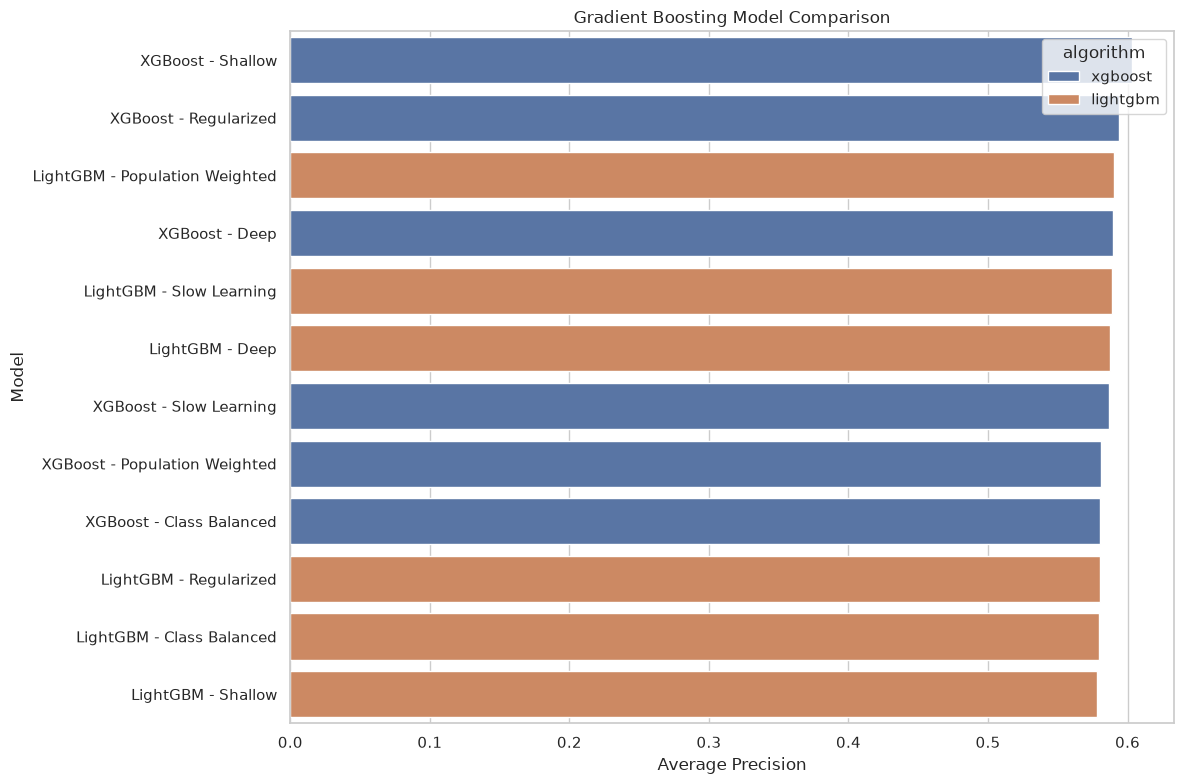

In [30]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=results_df,
    x="average_precision",
    y="model",
    hue="algorithm",
    dodge=False
)

plt.title("Gradient Boosting Model Comparison")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

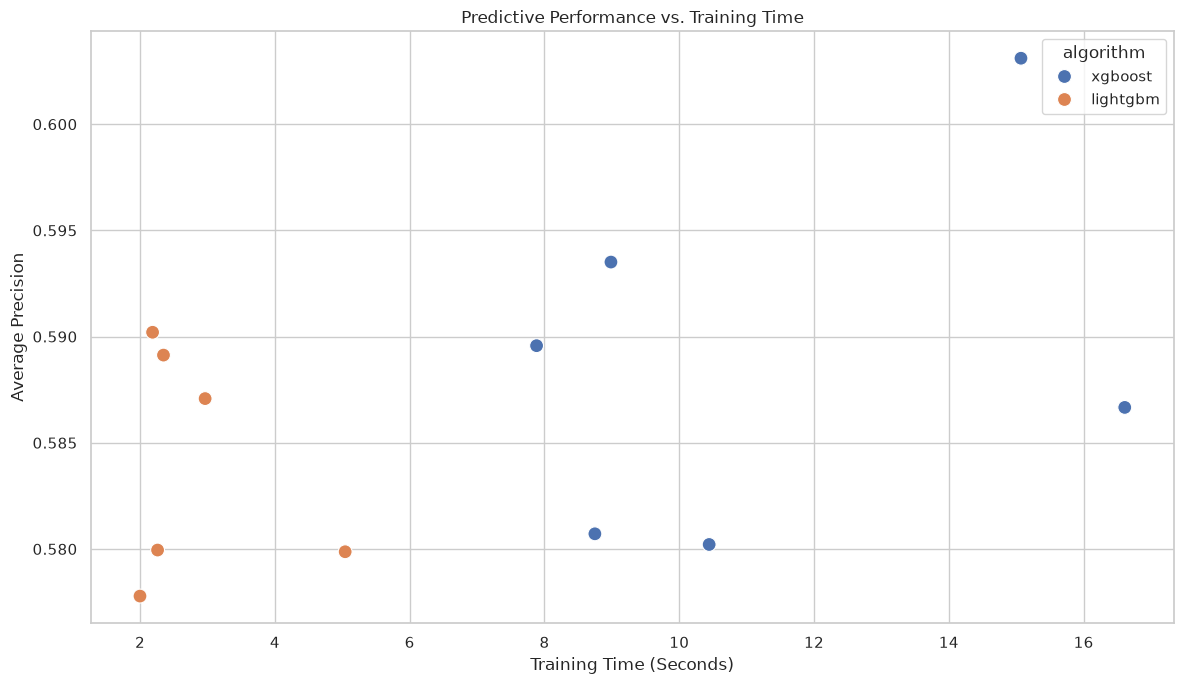

In [31]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=results_df,
    x="training_time_seconds",
    y="average_precision",
    hue="algorithm",
    s=100
)

plt.title("Predictive Performance vs. Training Time")
plt.xlabel("Training Time (Seconds)")
plt.ylabel("Average Precision")
plt.tight_layout()
plt.show()

In [32]:
best_initial_advanced = results_df.iloc[0]

best_config_name = best_initial_advanced["model"]
best_algorithm = best_initial_advanced["algorithm"]
best_weighting = best_initial_advanced["weighting"]

best_params = experiment_configs[best_config_name].copy()

print("Selected configuration:", best_config_name)

Selected configuration: XGBoost - Shallow


In [33]:
LARGER_SAMPLE_RATE = 0.10

larger_train_df = load_training_sample(
    sample_rate=LARGER_SAMPLE_RATE
)

X_larger = larger_train_df[feature_columns]
y_larger = larger_train_df[target_column]

print("Larger training shape:", X_larger.shape)

Larger training shape: (604778, 12)


In [34]:
larger_preprocessor = create_tree_preprocessor()

X_larger_processed = larger_preprocessor.fit_transform(
    X_larger
)

X_larger_val_processed = larger_preprocessor.transform(
    X_val
)

In [35]:
if best_weighting == "population":

    larger_weights = np.where(
        y_larger == 1,
        1.0,
        1.0 / LARGER_SAMPLE_RATE
    )

    larger_weights = (
        larger_weights / larger_weights.mean()
    )

else:

    larger_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_larger
    )

In [36]:
larger_model_name = f"{best_config_name} - 10% Sample"

train_boosting_model(
    model_name=larger_model_name,
    algorithm=best_algorithm,
    params=best_params,
    sample_weights=larger_weights,
    train_features=X_larger_processed,
    train_target=y_larger,
    fitted_preprocessor=larger_preprocessor,
    validation_features=X_larger_val_processed,
    sample_rate=LARGER_SAMPLE_RATE,
    weighting_name=best_weighting
)

model                    XGBoost - Shallow - 10% Sample
threshold                                           0.5
accuracy                                         0.9942
precision                                      0.979079
recall                                         0.150773
f1                                             0.261307
average_precision                              0.608008
roc_auc                                         0.96851
fraud_value_captured                            0.36795
true_positives                                      234
false_positives                                       5
true_negatives                                   226546
false_negatives                                    1318
algorithm                                       xgboost
training_time_seconds                          8.531136
best_iteration                                       75
training_rows                                    604778
negative_sample_rate                            

In [37]:
sampling_results = pd.DataFrame(results)

sampling_results = sampling_results[
    sampling_results["model"].isin([
        best_config_name,
        larger_model_name
    ])
]

sampling_results[[
    "model",
    "training_rows",
    "negative_sample_rate",
    "average_precision",
    "roc_auc",
    "training_time_seconds"
]]

,model,training_rows,negative_sample_rate,average_precision,roc_auc,training_time_seconds
4,XGBoost - Shallow,305142,0.05,0.603106,0.969962,15.069758
12,XGBoost - Shallow - 10% Sample,604778,0.10,0.608008,0.968510,8.531136


In [38]:
del larger_train_df
del X_larger
del y_larger
del X_larger_processed
del X_larger_val_processed
del larger_weights

gc.collect()

0

In [39]:
results_df = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

all_results = pd.concat(
    [baseline_results, results_df],
    ignore_index=True
).sort_values(
    "average_precision",
    ascending=False
).reset_index(drop=True)

all_results[comparison_columns].round(6)

,model,average_precision,roc_auc,precision,recall,f1,fraud_value_captured,false_positives,training_time_seconds,best_iteration
0,XGBoost - Shallow - 10% Sample,0.608008,0.968510,0.979079,0.150773,0.261307,0.367950,5,8.531136,75.0
1,XGBoost - Shallow,0.603106,0.969962,0.975309,0.203608,0.336887,0.455257,8,15.069758,164.0
2,XGBoost - Regularized,0.593509,0.967893,0.994792,0.123067,0.219037,0.289049,1,8.986205,102.0
3,LightGBM - Population Weighted,0.590204,0.971202,1.000000,0.106959,0.193248,0.325844,0,2.185153,21.0
4,XGBoost - Deep,0.589572,0.967772,0.990654,0.136598,0.240091,0.340465,2,7.882655,57.0
5,LightGBM - Slow Learning,0.589129,0.967860,1.000000,0.031572,0.061212,0.096577,0,2.347031,36.0
6,LightGBM - Deep,0.587081,0.972863,1.000000,0.034794,0.067248,0.106184,0,2.964712,16.0
7,XGBoost - Slow Learning,0.586666,0.970947,0.957983,0.220361,0.358303,0.467000,15,16.609640,190.0
8,XGBoost - Population Weighted,0.580715,0.966844,0.994595,0.118557,0.211860,0.287200,1,8.747880,58.0
9,XGBoost - Class Balanced,0.580213,0.975219,0.092029,0.885309,0.166727,0.987115,13556,10.443056,108.0


In [40]:
baseline_ap = baseline_results.loc[
    baseline_results["model"] == "Logistic Regression",
    "average_precision"
].iloc[0]

results_df["ap_improvement"] = (
    results_df["average_precision"] - baseline_ap
)

results_df["relative_ap_improvement_pct"] = (
    results_df["ap_improvement"] / baseline_ap * 100
)

results_df[[
    "model",
    "average_precision",
    "ap_improvement",
    "relative_ap_improvement_pct"
]].round(6)

,model,average_precision,ap_improvement,relative_ap_improvement_pct
0,XGBoost - Shallow - 10% Sample,0.608008,0.213648,54.175748
1,XGBoost - Shallow,0.603106,0.208745,52.932658
2,XGBoost - Regularized,0.593509,0.199149,50.499190
3,LightGBM - Population Weighted,0.590204,0.195843,49.661030
4,XGBoost - Deep,0.589572,0.195212,49.500885
5,LightGBM - Slow Learning,0.589129,0.194769,49.388529
6,LightGBM - Deep,0.587081,0.192721,48.869285
7,XGBoost - Slow Learning,0.586666,0.192305,48.763865
8,XGBoost - Population Weighted,0.580715,0.186355,47.254892
9,XGBoost - Class Balanced,0.580213,0.185852,47.127558


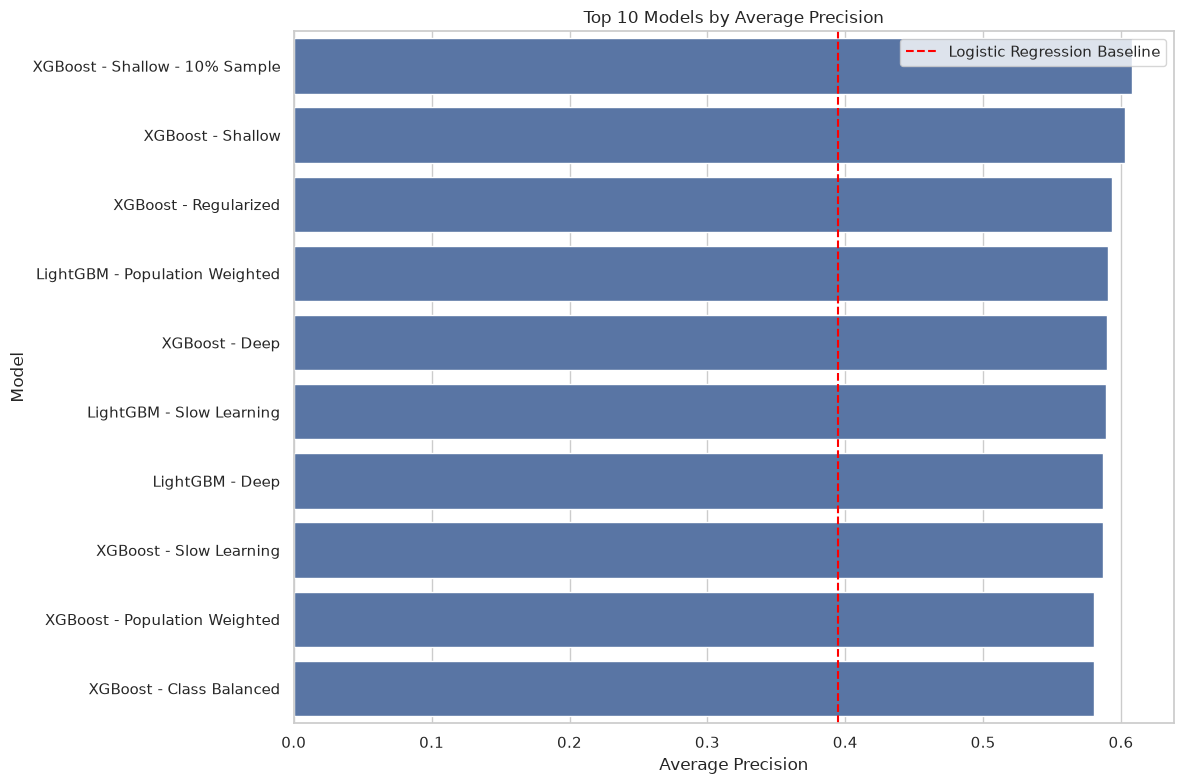

In [41]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=all_results.head(10),
    x="average_precision",
    y="model"
)

plt.axvline(
    baseline_ap,
    color="red",
    linestyle="--",
    label="Logistic Regression Baseline"
)

plt.title("Top 10 Models by Average Precision")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
best_xgb_row = (
    results_df[
        results_df["algorithm"] == "xgboost"
    ].iloc[0]
)

best_lgb_row = (
    results_df[
        results_df["algorithm"] == "lightgbm"
    ].iloc[0]
)

best_xgb_name = best_xgb_row["model"]
best_lgb_name = best_lgb_row["model"]

best_xgb_model = trained_models[best_xgb_name]
best_lgb_model = trained_models[best_lgb_name]

best_model_name = results_df.iloc[0]["model"]
best_model = trained_models[best_model_name]

print("Best XGBoost:", best_xgb_name)
print("Best LightGBM:", best_lgb_name)
print("Best Advanced Model:", best_model_name)

results_df.iloc[0]

Best XGBoost: XGBoost - Shallow - 10% Sample
Best LightGBM: LightGBM - Population Weighted
Best Advanced Model: XGBoost - Shallow - 10% Sample


model                          XGBoost - Shallow - 10% Sample
threshold                                                 0.5
accuracy                                               0.9942
precision                                            0.979079
recall                                               0.150773
f1                                                   0.261307
average_precision                                    0.608008
roc_auc                                               0.96851
fraud_value_captured                                  0.36795
true_positives                                            234
false_positives                                             5
true_negatives                                         226546
false_negatives                                          1318
algorithm                                             xgboost
training_time_seconds                                8.531136
best_iteration                                             75
training

In [43]:
baseline_model = joblib.load(
    MODEL_PATH / "baseline_logistic_regression.joblib"
)

baseline_probs = baseline_model.predict_proba(
    X_val
)[:, 1]

In [44]:
comparison_predictions = {
    "Logistic Regression": baseline_probs,
    best_xgb_name: predictions[best_xgb_name],
    best_lgb_name: predictions[best_lgb_name]
}

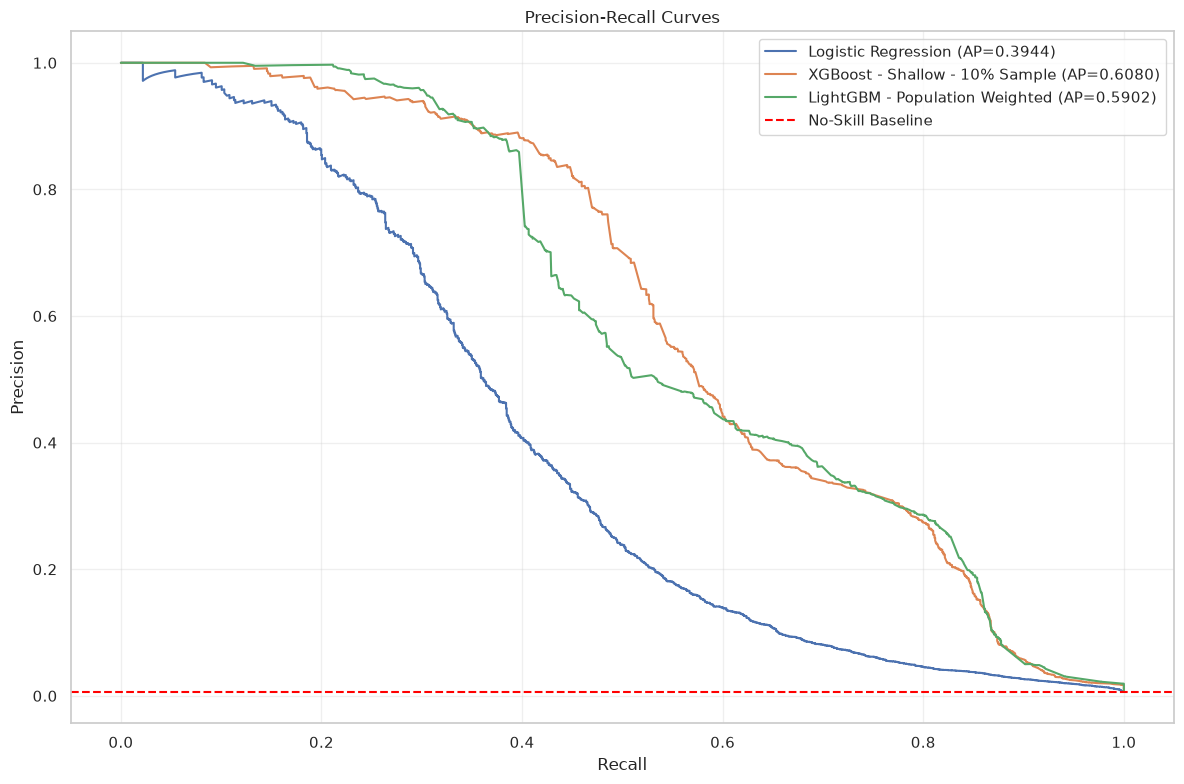

In [45]:
plt.figure(figsize=(12, 8))

for model_name, probabilities in comparison_predictions.items():

    precision, recall, _ = precision_recall_curve(
        y_val,
        probabilities
    )

    ap = average_precision_score(
        y_val,
        probabilities
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap:.4f})"
    )

plt.axhline(
    y_val.mean(),
    color="red",
    linestyle="--",
    label="No-Skill Baseline"
)

plt.title("Precision-Recall Curves")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

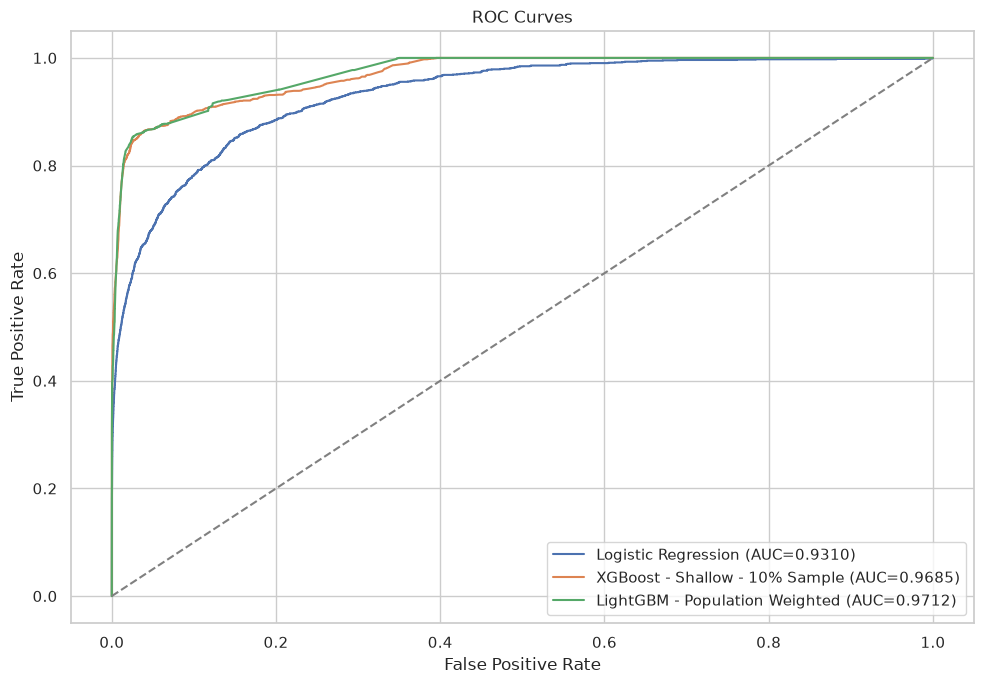

In [46]:
plt.figure(figsize=(10, 7))

for model_name, probabilities in comparison_predictions.items():

    fpr, tpr, _ = roc_curve(
        y_val,
        probabilities
    )

    auc = roc_auc_score(
        y_val,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC={auc:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

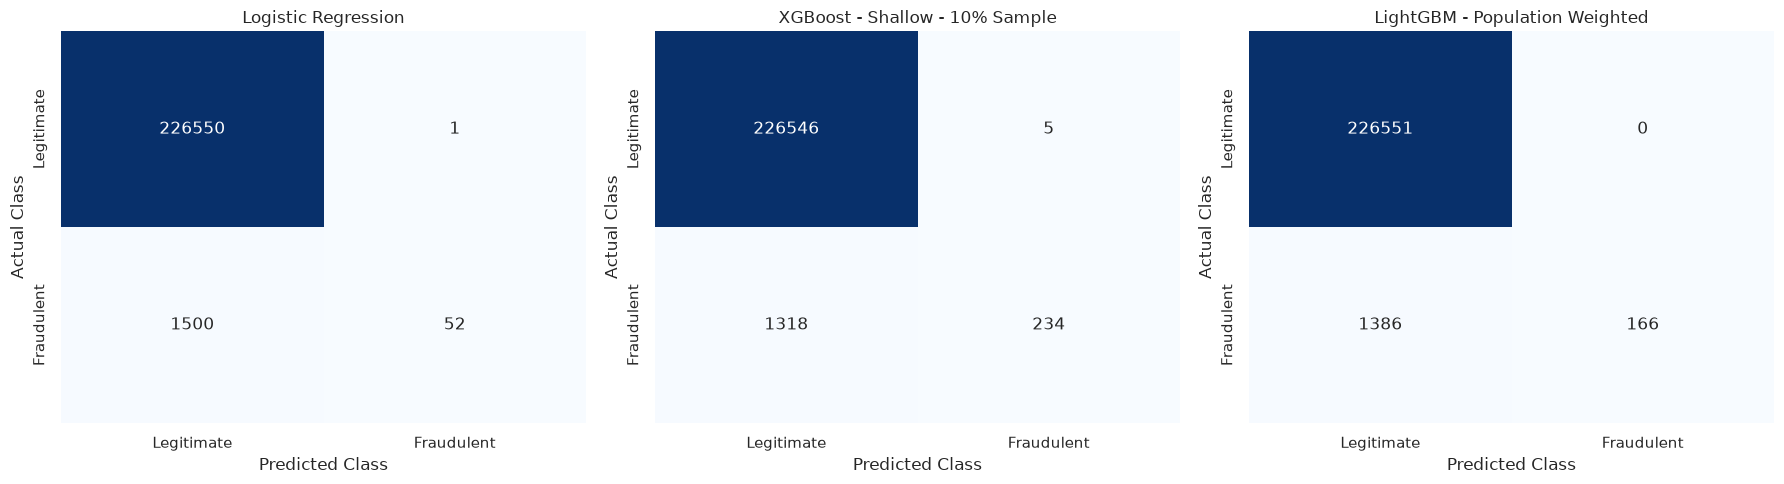

In [47]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, (model_name, probabilities) in zip(
    axes,
    comparison_predictions.items()
):

    y_pred = (probabilities >= 0.5).astype(int)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Legitimate", "Fraudulent"],
        yticklabels=["Legitimate", "Fraudulent"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [48]:
def evaluate_at_alert_budget(
    y_true,
    y_score,
    amounts,
    alert_rate=0.01
):

    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    amounts = np.asarray(amounts)

    alert_count = max(
        1,
        int(len(y_true) * alert_rate)
    )

    ranked_indices = np.argsort(
        -y_score,
        kind="stable"
    )

    selected_indices = ranked_indices[:alert_count]

    y_pred = np.zeros(len(y_true), dtype=int)
    y_pred[selected_indices] = 1

    return {
        "alert_rate": alert_rate,
        "alert_count": alert_count,
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "fraud_value_captured": (
            amounts[
                (y_true == 1) & (y_pred == 1)
            ].sum() /
            amounts[y_true == 1].sum()
        )
    }

In [49]:
budget_results = []

for model_name, probabilities in comparison_predictions.items():

    metrics = evaluate_at_alert_budget(
        y_val,
        probabilities,
        val_df["amount"],
        alert_rate=0.01
    )

    metrics["model"] = model_name

    budget_results.append(metrics)

budget_results_df = pd.DataFrame(budget_results)

budget_results_df

,alert_rate,alert_count,precision,recall,fraud_value_captured,model
0,0.01,2281,0.311705,0.458119,0.667058,Logistic Regression
1,0.01,2281,0.418238,0.614691,0.918656,XGBoost - Shallow - 10% Sample
2,0.01,2281,0.418676,0.615335,0.897810,LightGBM - Population Weighted


In [50]:
def get_feature_importance(model_pipeline):

    classifier = model_pipeline.named_steps["classifier"]

    feature_names = (
        model_pipeline
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance = classifier.feature_importances_

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": importance
    })

    total_importance = importance_df["importance"].sum()

    importance_df["normalized_importance"] = (
        importance_df["importance"] / total_importance
        if total_importance > 0 else 0
    )

    return importance_df.sort_values(
        "normalized_importance",
        ascending=False
    )

In [51]:
xgb_importance = get_feature_importance(
    best_xgb_model
)

lgb_importance = get_feature_importance(
    best_lgb_model
)

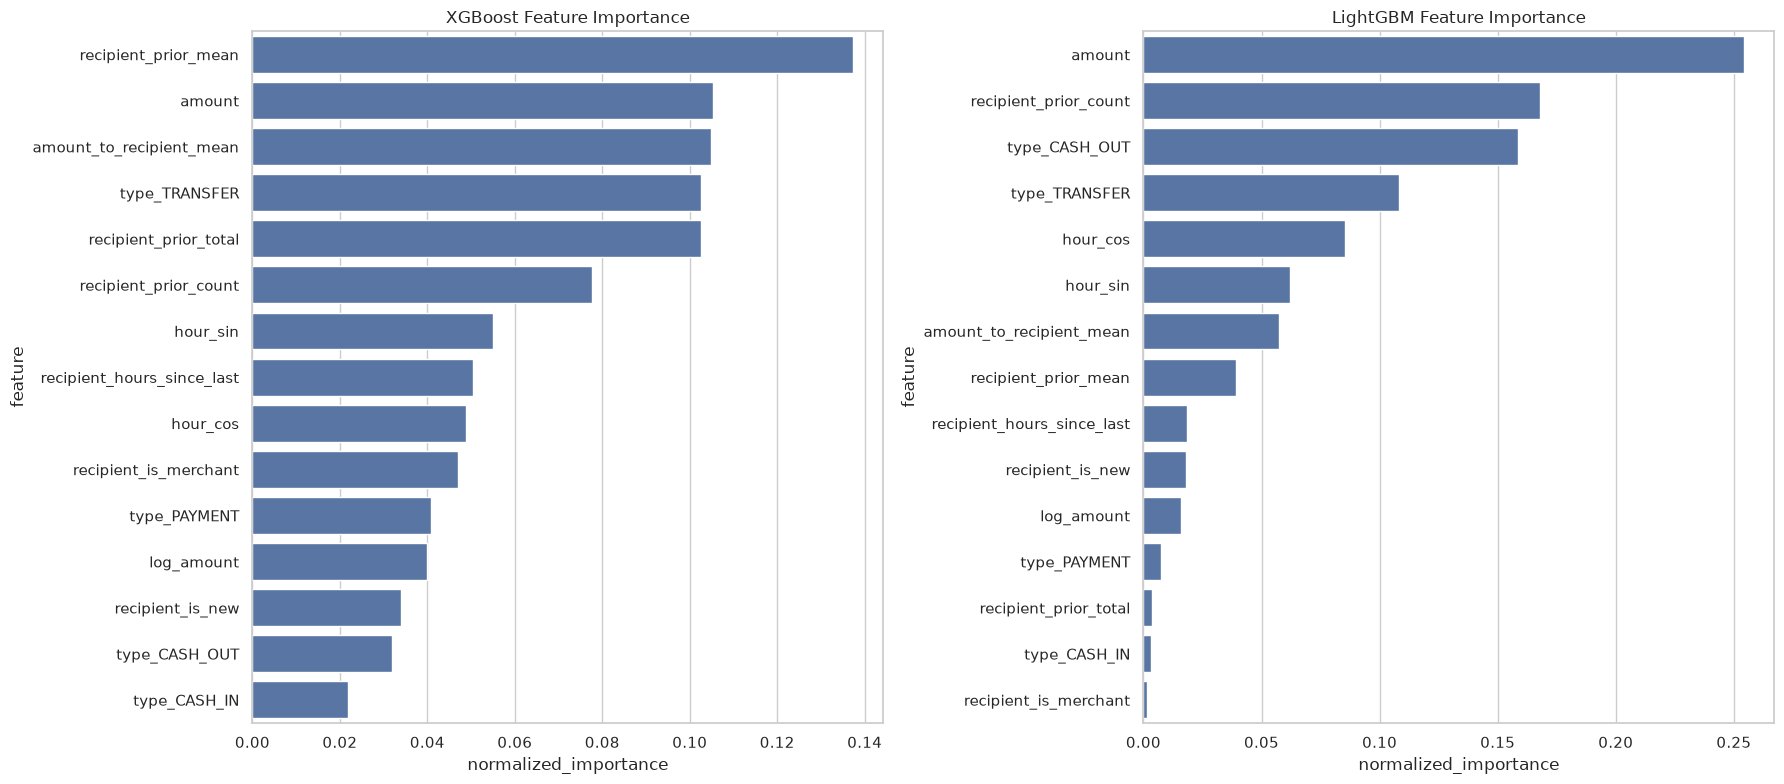

In [52]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 8)
)

sns.barplot(
    data=xgb_importance.head(15),
    x="normalized_importance",
    y="feature",
    ax=axes[0]
)

axes[0].set_title("XGBoost Feature Importance")

sns.barplot(
    data=lgb_importance.head(15),
    x="normalized_importance",
    y="feature",
    ax=axes[1]
)

axes[1].set_title("LightGBM Feature Importance")

plt.tight_layout()
plt.show()

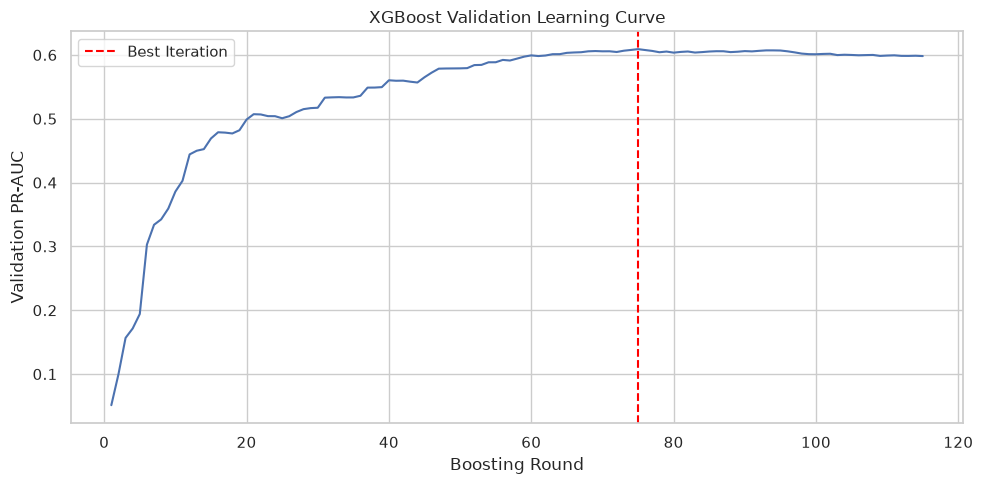

In [53]:
xgb_classifier = best_xgb_model.named_steps["classifier"]

xgb_history = xgb_classifier.evals_result()

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(
        1,
        len(xgb_history["validation_0"]["aucpr"]) + 1
    ),
    xgb_history["validation_0"]["aucpr"]
)

plt.axvline(
    xgb_classifier.best_iteration + 1,
    color="red",
    linestyle="--",
    label="Best Iteration"
)

plt.title("XGBoost Validation Learning Curve")
plt.xlabel("Boosting Round")
plt.ylabel("Validation PR-AUC")
plt.legend()
plt.tight_layout()
plt.show()

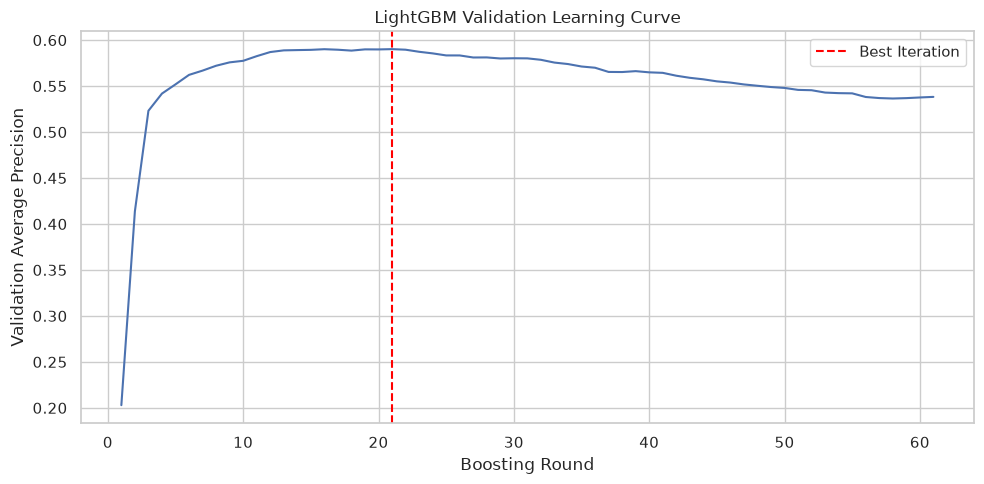

In [54]:
lgb_classifier = best_lgb_model.named_steps["classifier"]

lgb_history = lgb_classifier.evals_result_

plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(
        1,
        len(lgb_history["valid_0"]["average_precision"]) + 1
    ),
    lgb_history["valid_0"]["average_precision"]
)

plt.axvline(
    lgb_classifier.best_iteration_,
    color="red",
    linestyle="--",
    label="Best Iteration"
)

plt.title("LightGBM Validation Learning Curve")
plt.xlabel("Boosting Round")
plt.ylabel("Validation Average Precision")
plt.legend()
plt.tight_layout()
plt.show()

In [55]:
joblib.dump(
    best_xgb_model,
    MODEL_PATH / "best_xgboost.joblib"
)

joblib.dump(
    best_lgb_model,
    MODEL_PATH / "best_lightgbm.joblib"
)

joblib.dump(
    best_model,
    MODEL_PATH / "best_advanced_model.joblib"
)

['../models/best_advanced_model.joblib']

In [56]:
best_row = results_df.iloc[0]

advanced_metadata = {
    "model_name": best_model_name,
    "algorithm": best_row["algorithm"],
    "feature_columns": feature_columns,
    "hyperparameters": experiment_configs[best_model_name],
    "weighting_strategy": best_row["weighting"],
    "negative_sample_rate": float(
        best_row["negative_sample_rate"]
    ),
    "training_rows": int(
        best_row["training_rows"]
    ),
    "best_iteration": int(
        best_row["best_iteration"]
    ),
    "selection_metric": "average_precision",
    "validation_average_precision": float(
        best_row["average_precision"]
    ),
    "validation_roc_auc": float(
        best_row["roc_auc"]
    ),
    "baseline_average_precision": float(baseline_ap),
    "relative_ap_improvement_pct": float(
        best_row["relative_ap_improvement_pct"]
    ),
    "decision_threshold": 0.5,
    "threshold_optimized": False,
    "probability_calibrated": False,
    "test_set_evaluated": False,
    "random_state": RANDOM_STATE,
    "xgboost_version": xgb.__version__,
    "lightgbm_version": lgb.__version__
}

with open(
    MODEL_PATH / "advanced_model_metadata.json",
    "w"
) as f:
    json.dump(advanced_metadata, f, indent=4)

In [57]:
results_df.to_csv(
    RESULTS_PATH / "advanced_model_results.csv",
    index=False
)

all_results.to_csv(
    RESULTS_PATH / "all_model_results.csv",
    index=False
)

budget_results_df.to_csv(
    RESULTS_PATH / "alert_budget_results.csv",
    index=False
)

xgb_importance.to_csv(
    RESULTS_PATH / "xgboost_feature_importance.csv",
    index=False
)

lgb_importance.to_csv(
    RESULTS_PATH / "lightgbm_feature_importance.csv",
    index=False
)

In [58]:
with open(
    RESULTS_PATH / "advanced_experiment_configs.json",
    "w"
) as f:
    json.dump(experiment_configs, f, indent=4)

## Key Findings

### Training Strategy and Computational Efficiency
- Evaluated XGBoost and LightGBM using the 12 leakage-controlled predictive features developed during feature engineering.
- Reused the same 5% majority-class undersampling strategy and random seed established during baseline modeling.
- The initial training dataset contains 305,142 transactions, including all 5,007 fraudulent training transactions.
- Retained the complete validation dataset of 228,103 transactions.
- One-hot encoding expanded the 12 original predictive features into 16 transformed features.
- Numerical scaling and missing-value imputation were unnecessary because both gradient boosting algorithms support native missing-value handling and do not require standardized features.
- Used histogram-based tree construction, limited parallel processing, and early stopping to accommodate local computational constraints.
- Successfully completed 13 gradient boosting experiments without encountering memory-related failures.
- The held-out test dataset was not used during model development.

### XGBoost Performance
- XGBoost substantially outperformed the logistic regression baseline across all evaluated configurations.
- The strongest XGBoost configuration used shallow trees, population weighting, and a 10% legitimate transaction sample.
- The best XGBoost model achieved the following validation performance at a classification threshold of 0.5:
  - Average Precision: 0.608008
  - ROC-AUC: 0.968510
  - Accuracy: 99.4200%
  - Precision: 97.9079%
  - Recall: 15.0773%
  - F1-score: 0.261307
  - Fraudulent transaction value captured: 36.7950%
- Correctly identified 234 fraudulent transactions while generating only 5 false positives.
- Missed 1,318 fraudulent transactions at the default classification threshold.
- Selected XGBoost as the strongest advanced model based on validation Average Precision.

### LightGBM Performance
- The initial population-weighted LightGBM configuration achieved the strongest performance among the evaluated LightGBM models.
- Model performance at a threshold of 0.5:
  - Average Precision: 0.590204
  - ROC-AUC: 0.971202
  - Precision: 100.00%
  - Recall: 10.6959%
  - F1-score: 0.193248
  - Fraudulent transaction value captured: 32.5844%
- Correctly identified 166 fraudulent transactions with zero false positives.
- Selected 21 boosting rounds through early stopping.
- Recorded a training time of approximately 2.19 seconds.
- LightGBM demonstrated competitive predictive performance and strong computational efficiency.

### Impact of Class Weighting

| Model | Average Precision | ROC-AUC | Precision | Recall | False Positives |
|---|---:|---:|---:|---:|---:|
| XGBoost - Population Weighted | 0.580715 | 0.966844 | 0.994595 | 0.118557 | 1 |
| XGBoost - Class Balanced | 0.580213 | 0.975219 | 0.092029 | 0.885309 | 13,556 |
| LightGBM - Population Weighted | 0.590204 | 0.971202 | 1.000000 | 0.106959 | 0 |
| LightGBM - Class Balanced | 0.579871 | 0.975264 | 0.093272 | 0.883376 | 13,328 |

- Class-balanced weighting substantially increased fraud recall and ROC-AUC for both algorithms.
- However, balanced models generated considerably more false-positive alerts.
- Population weighting achieved slightly higher Average Precision for both initial algorithms.
- Class weighting affects the distribution of predicted scores and the resulting classification decisions.
- Population weighting was selected for subsequent hyperparameter experiments based on validation Average Precision.
- These results reinforce the importance of evaluating ranking performance separately from classification thresholds.

### Hyperparameter Optimization
- Conducted a controlled manual hyperparameter search to investigate tree complexity, regularization, and learning rate.
- Evaluated shallow, deep, regularized, and slow-learning configurations for both algorithms.

| Configuration | XGBoost AP | LightGBM AP |
|---|---:|---:|
| Initial Population Weighted | 0.580715 | 0.590204 |
| Shallow | 0.603106 | 0.577783 |
| Deep | 0.589572 | 0.587081 |
| Regularized | 0.593509 | 0.579951 |
| Slow Learning | 0.586666 | 0.589129 |

- Shallow XGBoost achieved the highest Average Precision among the 5% sampling experiments.
- Increasing XGBoost tree depth did not improve performance relative to the shallow configuration.
- The initial LightGBM configuration outperformed its manually tuned alternatives.
- Greater model complexity did not consistently produce better validation performance.
- The strongest XGBoost configuration used:
  - Maximum tree depth: 3
  - Minimum child weight: 10
  - Learning rate: 0.05
  - Maximum estimators: 800
  - Subsample: 0.8
  - Column subsample: 0.8
  - L1 regularization: 0.1
  - L2 regularization: 1.0
  - Early stopping patience: 40 rounds

### Early Stopping and Model Complexity
- Applied early stopping to control unnecessary boosting iterations and reduce overfitting.
- Monitored validation PR-AUC for XGBoost and validation Average Precision for LightGBM.
- Used Scikit-learn Average Precision consistently for final model comparisons because the monitored metrics use different integration conventions.
- The strongest 5% sample XGBoost model selected 164 boosting rounds.
- The strongest 10% sample XGBoost model selected 75 boosting rounds.
- The strongest LightGBM model selected 21 boosting rounds.
- Early stopping allowed models to achieve competitive performance without using the maximum configured number of estimators.

### Training Sample Size Sensitivity

| Metric | 5% Legitimate Sample | 10% Legitimate Sample |
|---|---:|---:|
| Training Transactions | 305,142 | 604,778 |
| Average Precision | 0.603106 | 0.608008 |
| ROC-AUC | 0.969962 | 0.968510 |
| Training Time (Seconds) | 15.07 | 8.53 |
| Best Boosting Round | 164 | 75 |

- Increasing the legitimate transaction retention rate from 5% to 10% produced a modest improvement in Average Precision.
- Average Precision increased by approximately 0.81% relative to the smaller training sample.
- The larger sample slightly reduced ROC-AUC despite improving Average Precision.
- The larger training sample recorded a shorter training time, likely influenced by the substantially smaller number of selected boosting rounds.
- Training time measurements represent individual experimental runs and should not be interpreted as general performance guarantees.
- Selected the 10% sample XGBoost model as the strongest advanced model.
- Additional experiments with larger training samples may be useful, but their computational cost and incremental predictive value should be evaluated.

### Comparison Against Baseline Models

| Model | Average Precision | ROC-AUC |
|---|---:|---:|
| XGBoost - Shallow - 10% Sample | 0.608008 | 0.968510 |
| XGBoost - Shallow | 0.603106 | 0.969962 |
| XGBoost - Regularized | 0.593509 | 0.967893 |
| LightGBM - Population Weighted | 0.590204 | 0.971202 |
| Logistic Regression | 0.394360 | 0.931000 |
| Balanced Logistic Regression | 0.326533 | 0.948812 |
| PaySim Fraud Rule | 0.008084 | 0.500644 |

- All 13 gradient boosting experiments outperformed ordinary logistic regression in validation Average Precision.
- The strongest XGBoost model improved Average Precision by 0.213648, representing a relative improvement of 54.18%.
- The strongest LightGBM model improved Average Precision by approximately 49.66% relative to logistic regression.
- These results demonstrate the predictive advantages of modeling nonlinear relationships and feature interactions within the PaySim dataset.

### Precision-Recall Trade-offs
- Population-weighted gradient boosting models generally achieved high precision but limited recall at the default threshold of 0.5.
- Class-balanced models substantially improved recall at the expense of precision and investigation workload.
- The best XGBoost model was selected using Average Precision rather than accuracy or threshold-dependent metrics.
- The XGBoost slow-learning configuration achieved the highest F1-score among the advanced experiments at the default threshold, approximately 0.3583.
- The strongest Average Precision model did not necessarily achieve the strongest F1-score, recall, or ROC-AUC.
- Future model comparisons should incorporate optimized decision thresholds and operational constraints.

### Fraudulent Transaction Value Captured
- Ordinary logistic regression captured approximately 14.78% of fraudulent validation transaction value at the default threshold.
- The strongest XGBoost model captured approximately 36.80%.
- The strongest LightGBM model captured approximately 32.58%.
- Class-balanced XGBoost and LightGBM captured more than 98% of fraudulent transaction value, but generated thousands of false-positive alerts.
- Financial transaction value provides an important complement to conventional classification metrics.
- Detected fraudulent transaction value should not be interpreted directly as financial losses prevented.

### Fixed Investigation Budget Performance
- Evaluated the strongest logistic regression, XGBoost, and LightGBM models under an identical hypothetical investigation budget.
- Each model was restricted to flagging the highest-risk 1% of validation transactions, corresponding to 2,281 alerts.

| Model | Alerts | Precision | Recall | Fraud Value Captured |
|---|---:|---:|---:|---:|
| Logistic Regression | 2,281 | 31.17% | 45.81% | 66.71% |
| XGBoost | 2,281 | 41.82% | 61.47% | 91.87% |
| LightGBM | 2,281 | 41.87% | 61.53% | 89.78% |

- Both gradient boosting models substantially outperformed logistic regression under the same investigation capacity.
- XGBoost captured approximately 91.87% of fraudulent transaction value while investigating only 1% of validation transactions.
- XGBoost improved fraudulent transaction value captured by approximately 25.16 percentage points relative to logistic regression.
- LightGBM achieved marginally higher transaction-level precision and recall than XGBoost under the fixed investigation budget.
- XGBoost achieved the highest fraudulent transaction value captured.
- Fixed-budget evaluation provides a more operationally meaningful comparison than applying an identical probability threshold to differently weighted models.
- The 1% investigation budget represents a hypothetical business constraint rather than an actual financial institution requirement.

### Feature Importance
- XGBoost and LightGBM assigned substantial importance to transaction characteristics and engineered historical recipient features.

The highest-ranked XGBoost features were:
- recipient_prior_mean
- amount
- amount_to_recipient_mean
- type_TRANSFER
- recipient_prior_total
- recipient_prior_count

The highest-ranked LightGBM features were:
- amount
- recipient_prior_count
- type_CASH_OUT
- type_TRANSFER
- hour_cos
- hour_sin

- Historical recipient behavior contributes meaningfully to the learned gradient boosting models.
- XGBoost assigned substantial importance to historical recipient transaction amounts and deviations from previous recipient behavior.
- LightGBM assigned the greatest importance to transaction amount and historical recipient transaction frequency.
- Temporal features also contributed to predictive performance.
- Built-in feature importance does not establish causality or independently prove incremental feature effectiveness.
- Gain importance definitions differ between algorithms and should primarily be interpreted within each model.
- Future SHAP analysis will provide more detailed global and transaction-level explanations.

### Model Limitations
- Majority-class undersampling discards potentially useful legitimate transaction information.
- The validation dataset was reused for early stopping, hyperparameter selection, and training sample size selection, potentially introducing optimistic validation estimates.
- Only a limited manual hyperparameter search was conducted.
- Training time comparisons are based on individual experimental runs.
- Predicted probabilities have not been calibrated.
- Classification thresholds have not been optimized.
- Built-in feature importance may be affected by correlated predictors and differences in algorithm-specific importance calculations.
- Temporal features may capture simulator-specific behavior.
- PaySim is a synthetic dataset, limiting conclusions about real-world generalization.
- Substantial temporal distribution shift remains an important modeling challenge.
- Final generalization performance remains unknown because the held-out test dataset has not been evaluated.

### Model Artifacts and Reproducibility
- Saved the strongest XGBoost and LightGBM pipelines using Joblib.
- Saved the overall strongest advanced model as a separate model artifact.
- Preserved the fitted categorical preprocessing transformations within each model pipeline.
- Exported advanced model results, combined baseline and advanced model results, fixed-budget evaluation results, and feature importance rankings.
- Saved hyperparameter configurations, model metadata, sampling rates, selected boosting rounds, and library versions.
- Maintained consistent random seeds, feature definitions, evaluation metrics, and chronological dataset partitions.

### Implications for Model Evaluation and Deployment
- Retain XGBoost as the leading supervised fraud detection model based on validation Average Precision.
- Retain LightGBM as a competitive alternative with strong computational efficiency.
- Preserve logistic regression as an interpretable statistical baseline.
- Investigate unsupervised anomaly detection as an alternative or complementary approach.
- Perform probability calibration before interpreting model scores as fraud probabilities.
- Optimize classification thresholds using validation data and hypothetical operational costs.
- Evaluate models across multiple investigation budgets.
- Investigate global and local model explanations using SHAP.
- Assess model robustness under temporal distribution shift.
- Preserve the held-out test dataset until model selection and operational decision policies are finalized.

## Conclusion

The advanced modeling phase demonstrated that gradient-boosted decision trees substantially outperform linear machine learning models for fraud detection within the PaySim dataset.

The strongest XGBoost model achieved a validation Average Precision of 0.608008, representing a 54.18% relative improvement over the logistic regression baseline.

Under a hypothetical investigation budget of 1% of transactions, XGBoost captured approximately 91.87% of fraudulent transaction value, compared to 66.71% for logistic regression.

Historical recipient behavior, transaction characteristics, and temporal features contributed to the learned models, supporting the leakage-controlled feature engineering strategy.

Although the advanced models demonstrate strong validation performance, probability calibration, threshold optimization, explainability, and held-out temporal evaluation remain necessary before selecting a final deployment configuration.

The next phase will investigate unsupervised anomaly detection and determine whether anomaly-based approaches provide additional predictive value beyond supervised classification.